## 01_exploratory_data_analysis

##### importing require libraries 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob 
import os

In [2]:
# set style for Eda
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('muted')

In [3]:
# loading all dataset from directory
data_path="../data/raw/"

try:
    df_companies = pd.read_excel(os.path.join(data_path, "companies.xlsx"))
    df_pl = pd.read_excel(os.path.join(data_path, "profitandloss.xlsx"), skiprows=1)
    df_bs = pd.read_excel(os.path.join(data_path, "balancesheet.xlsx"), skiprows=1)
    df_cf = pd.read_excel(os.path.join(data_path, "cashflow.xlsx"), skiprows=1)
    
    print("✅ All core financial statements loaded successfully!")
    print("-" * 50)
    print(f"Companies Shape: {df_companies.shape}")
    print(f"P&L Shape: {df_pl.shape}")
    print(f"Balance Sheet Shape: {df_bs.shape}")
    print(f"Cash Flow Shape: {df_cf.shape}")
    
except Exception as e:
    print(f"❌ Error loading files: {e}\nCheck if files are in data/raw/")

✅ All core financial statements loaded successfully!
--------------------------------------------------
Companies Shape: (93, 12)
P&L Shape: (1276, 15)
Balance Sheet Shape: (1312, 13)
Cash Flow Shape: (1187, 7)


### Null value heatmap for the P&L Statement

In [4]:
df_pl.head()

,id,company_id,year,sales,expenses,operating_profit,opm_percentage,other_income,interest,depreciation,profit_before_tax,tax_percentage,net_profit,eps,dividend_payout
0,61,ABB,Dec 2012,1653,1451,202.0,12.0,33,0,19,215,33.0,145,68.0,25.0
1,62,ABB,Mar 2014,2276,2009,267.0,12.0,49,0,22,295,33.0,198,93.0,25.0
2,63,ABB,Mar 2015,2289,1977,312.0,14.0,48,0,15,344,34.0,229,108.0,29.0
3,64,ABB,Mar 2016,2614,2250,365.0,14.0,50,3,14,398,36.0,255,120.0,29.0
4,65,ABB,Mar 2017,2903,2505,398.0,14.0,57,2,16,436,37.0,277,130.0,31.0


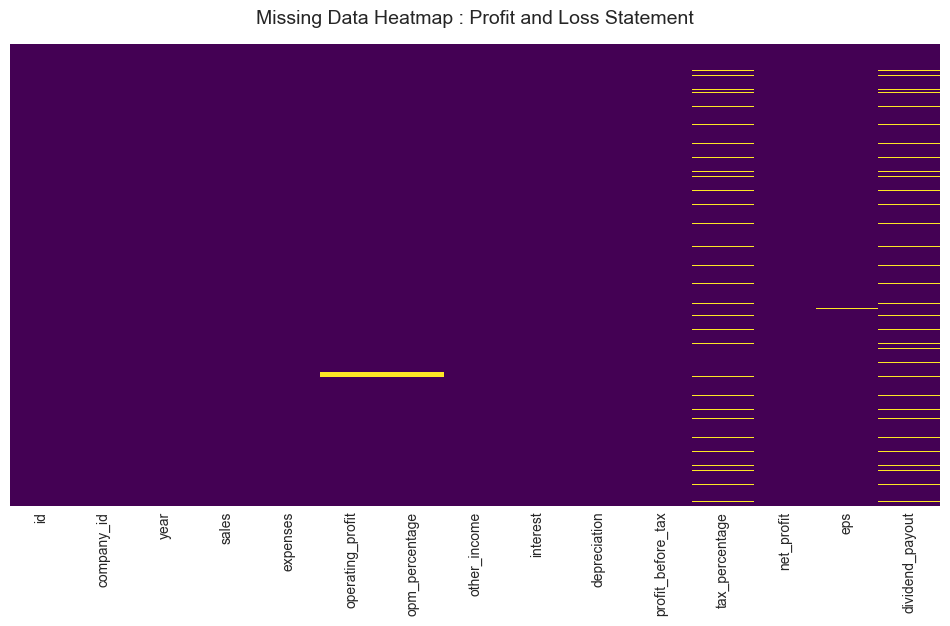

In [5]:
plt.figure(figsize=(12,6))
sns.heatmap(df_pl.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title("Missing Data Heatmap : Profit and Loss Statement", fontsize =14 , pad=15)
plt.show()

### 1] years coverage analysis
#### count how many years of data each company has in the pnl state ment

In [6]:
years_counts = df_pl.groupby('company_id')['year'].nunique().sort_values(ascending=False)


📊Year coverage summery:
Minimum years recorded for a company: 3
Maximum years recorded for a company: 13
Average years recorded : 12.63
__________________________________________________


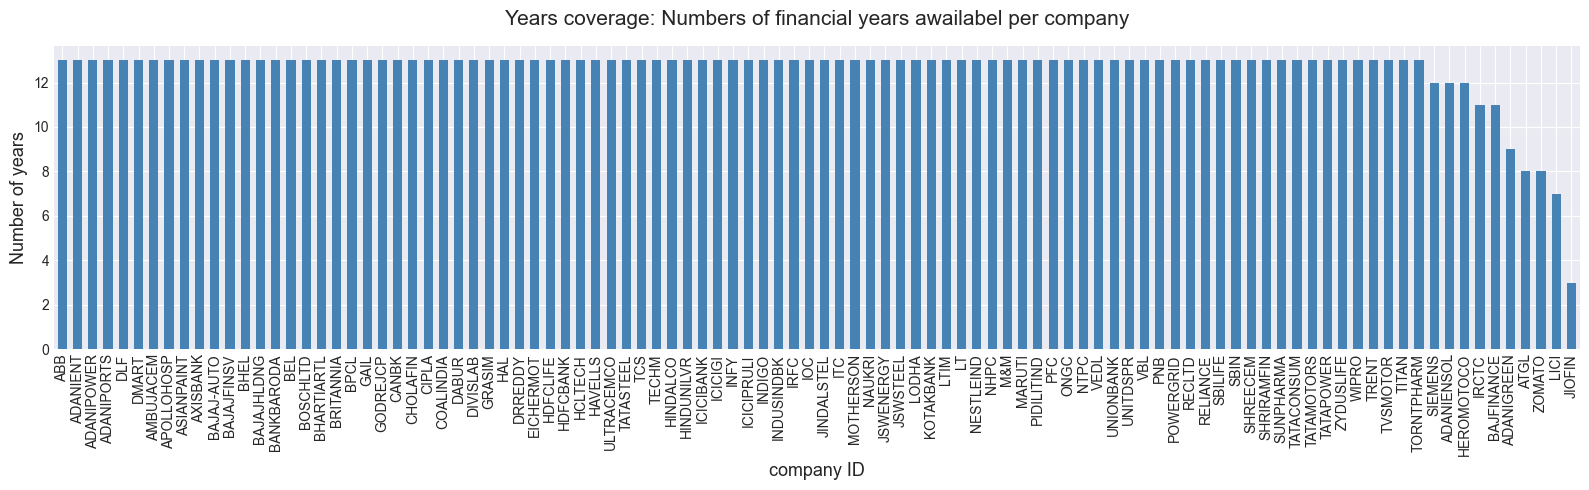

In [7]:
plt.figure(figsize=(16,5))
years_counts.plot(kind='bar', color='steelblue', width=0.6)
plt.title("Years coverage: Numbers of financial years awailabel per company", fontsize=15,pad=15)
plt.xlabel('company ID',fontsize=13)
plt.ylabel('Number of years', fontsize=13)
plt.xticks(rotation=90, fontsize=10)
plt.tight_layout()
plt.show

print(f"📊Year coverage summery:")
print(f"Minimum years recorded for a company: {years_counts.min()}")
print(f"Maximum years recorded for a company: {years_counts.max()}")
print(f"Average years recorded : {years_counts.mean()}")
print("_" * 50)


### 2] Revenue distribution  analysis

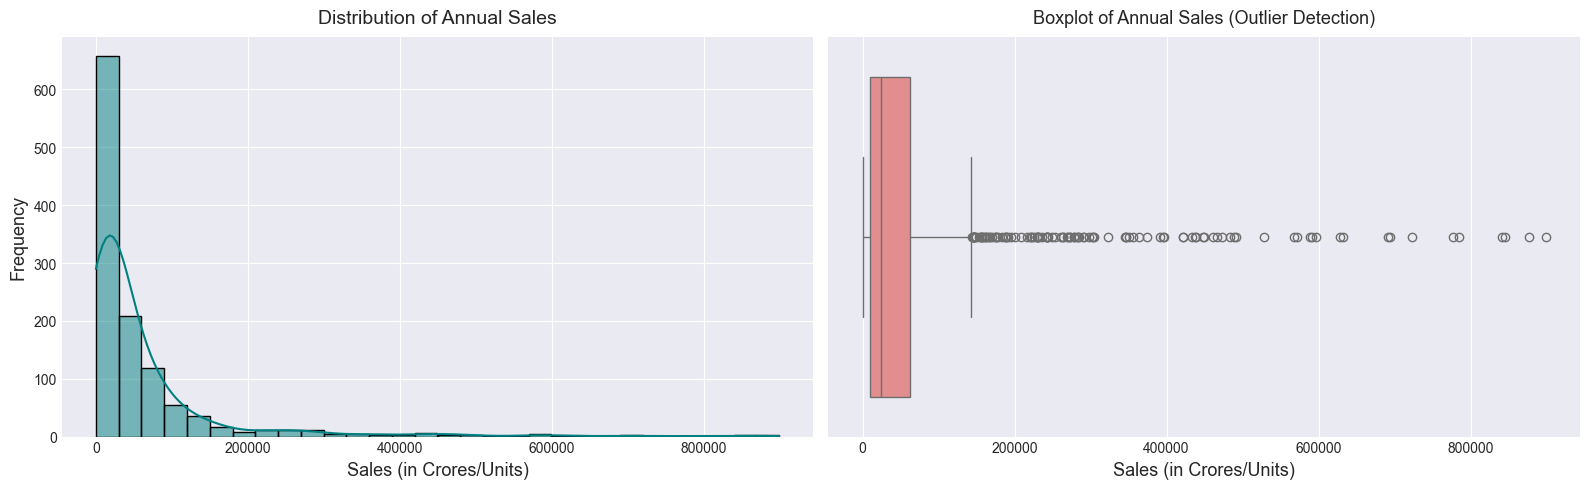

In [8]:


df_annual_sales = df_pl[df_pl['year'] != 'TTM']

# Create the main figure container
plt.figure(figsize=(16, 5))


plt.subplot(1, 2, 1)
sns.histplot(data=df_annual_sales, x='sales', kde=True, color='teal', bins=30)
plt.title("Distribution of Annual Sales", fontsize=14, pad=10)
plt.xlabel("Sales (in Crores/Units)", fontsize=13)
plt.ylabel("Frequency", fontsize=13)


plt.subplot(1, 2, 2)
sns.boxplot(data=df_annual_sales, x='sales', color='lightcoral')
plt.title("Boxplot of Annual Sales (Outlier Detection)", fontsize=13, pad=10)
plt.xlabel("Sales (in Crores/Units)", fontsize=13)

plt.tight_layout()
plt.show()

### 3] lets see messy strings


In [9]:
# load analysis table
df_analysis = pd.read_excel(os.path.join(data_path,'analysis.xlsx'),skiprows=1)

# 2. Preview the messy string columns, dropping empty rows just for a clean look
messy_columns = ['company_id', 'compounded_sales_growth', 'compounded_profit_growth', 'roe']
print("🔍 Inspecting the raw text formats in the Analysis table:")
print(df_analysis[messy_columns].dropna().head(10).to_string())

🔍 Inspecting the raw text formats in the Analysis table:
  company_id          compounded_sales_growth  compounded_profit_growth                    roe
0   HDFCBANK                    10 Years: 21%             10 Years: 22%      10 Years:     17%
1    SBILIFE               5 Years:       24%    5 Years:            6%   5 Years          14%
2    SBILIFE               3 Years:       17%    3 Years:            9%   3 Years:         13%
3    SBILIFE              TTM:            43%  TTM:                 18%    Last Year:      12%
4        TCS   10 Years:     11%                  10 Years:          9%    10 Years:       40%
5        TCS  5 Years:       10%                 5 Years:            8%  5 Years:          44%
6        TCS  3 Years:       14%                3 Years:            12%  3 Years:          47%
7        TCS  TTM:            5%                TTM:                 8%   Last Year:       52%
8      WIPRO                 10 Years:     8%     10 Years:          3%   10 Years:     

### 4] Correlation matrix: which metrics are correlated? (e.g. does ROE correlate with OPM%? Does D/E correlate with poor health?


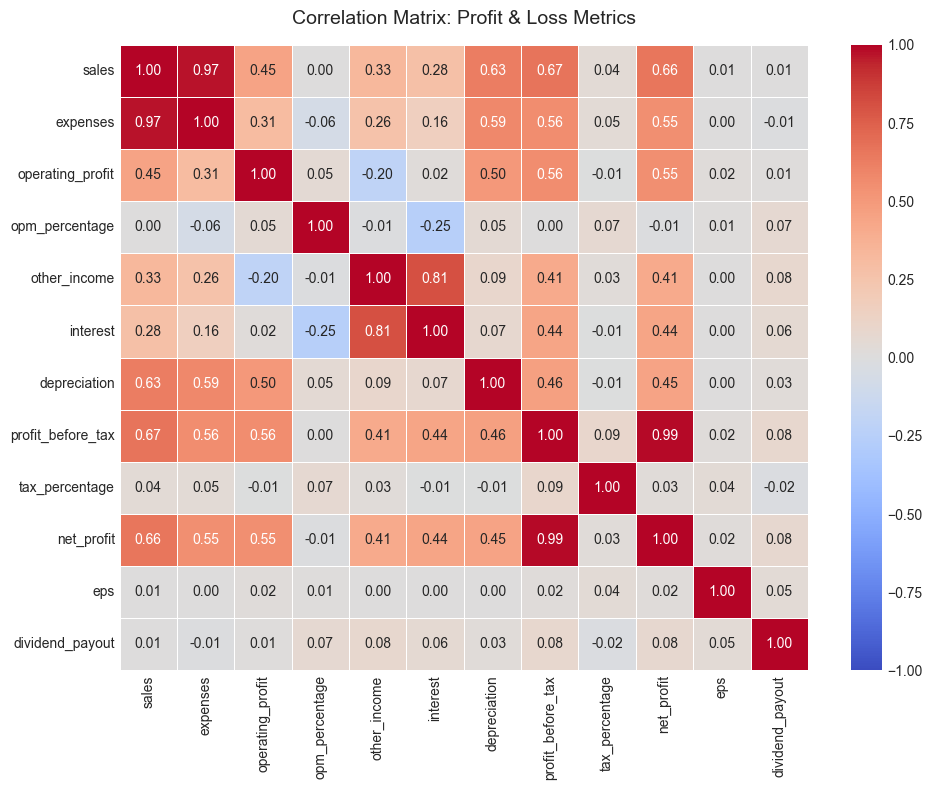

C:\Users\91935\AppData\Local\Temp\ipykernel_17020\285907186.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_sales.index.astype(str), y=top_10_sales.values, palette='viridis')


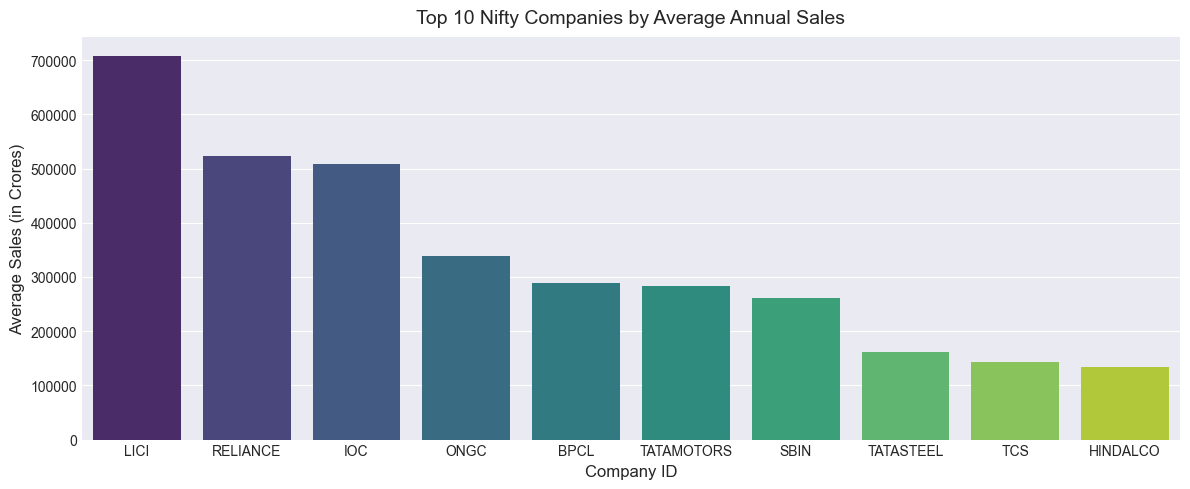

In [10]:

# 1. Correlation Matrix of Core P&L Metrics

plt.figure(figsize=(10, 8))

# Select only the numeric columns, ignoring ID columns
numeric_pl = df_pl.select_dtypes(include=['float64', 'int64']).drop(columns=['id', 'company_id'], errors='ignore')
corr_matrix = numeric_pl.corr()

# Draw the heatmap with values annotated inside
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Matrix: Profit & Loss Metrics", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

# 2. Top 10 Companies by Average Annual Sales

# Filter out 'TTM' to keep only historical fiscal years, group by company, and average their sales
historical_pl = df_pl[df_pl['year'] != 'TTM']
top_10_sales = historical_pl.groupby('company_id')['sales'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 5))
# We convert the index to string so seaborn treats Company IDs as distinct categories, not a continuous number line
sns.barplot(x=top_10_sales.index.astype(str), y=top_10_sales.values, palette='viridis')
plt.title("Top 10 Nifty Companies by Average Annual Sales", fontsize=14, pad=10)
plt.xlabel("Company ID", fontsize=12)
plt.ylabel("Average Sales (in Crores)", fontsize=12)
plt.tight_layout()
plt.show()

### 5] Top 10 and bottom 10 companies by: revenue, net profit, ROE, OPM%, 3Y growth

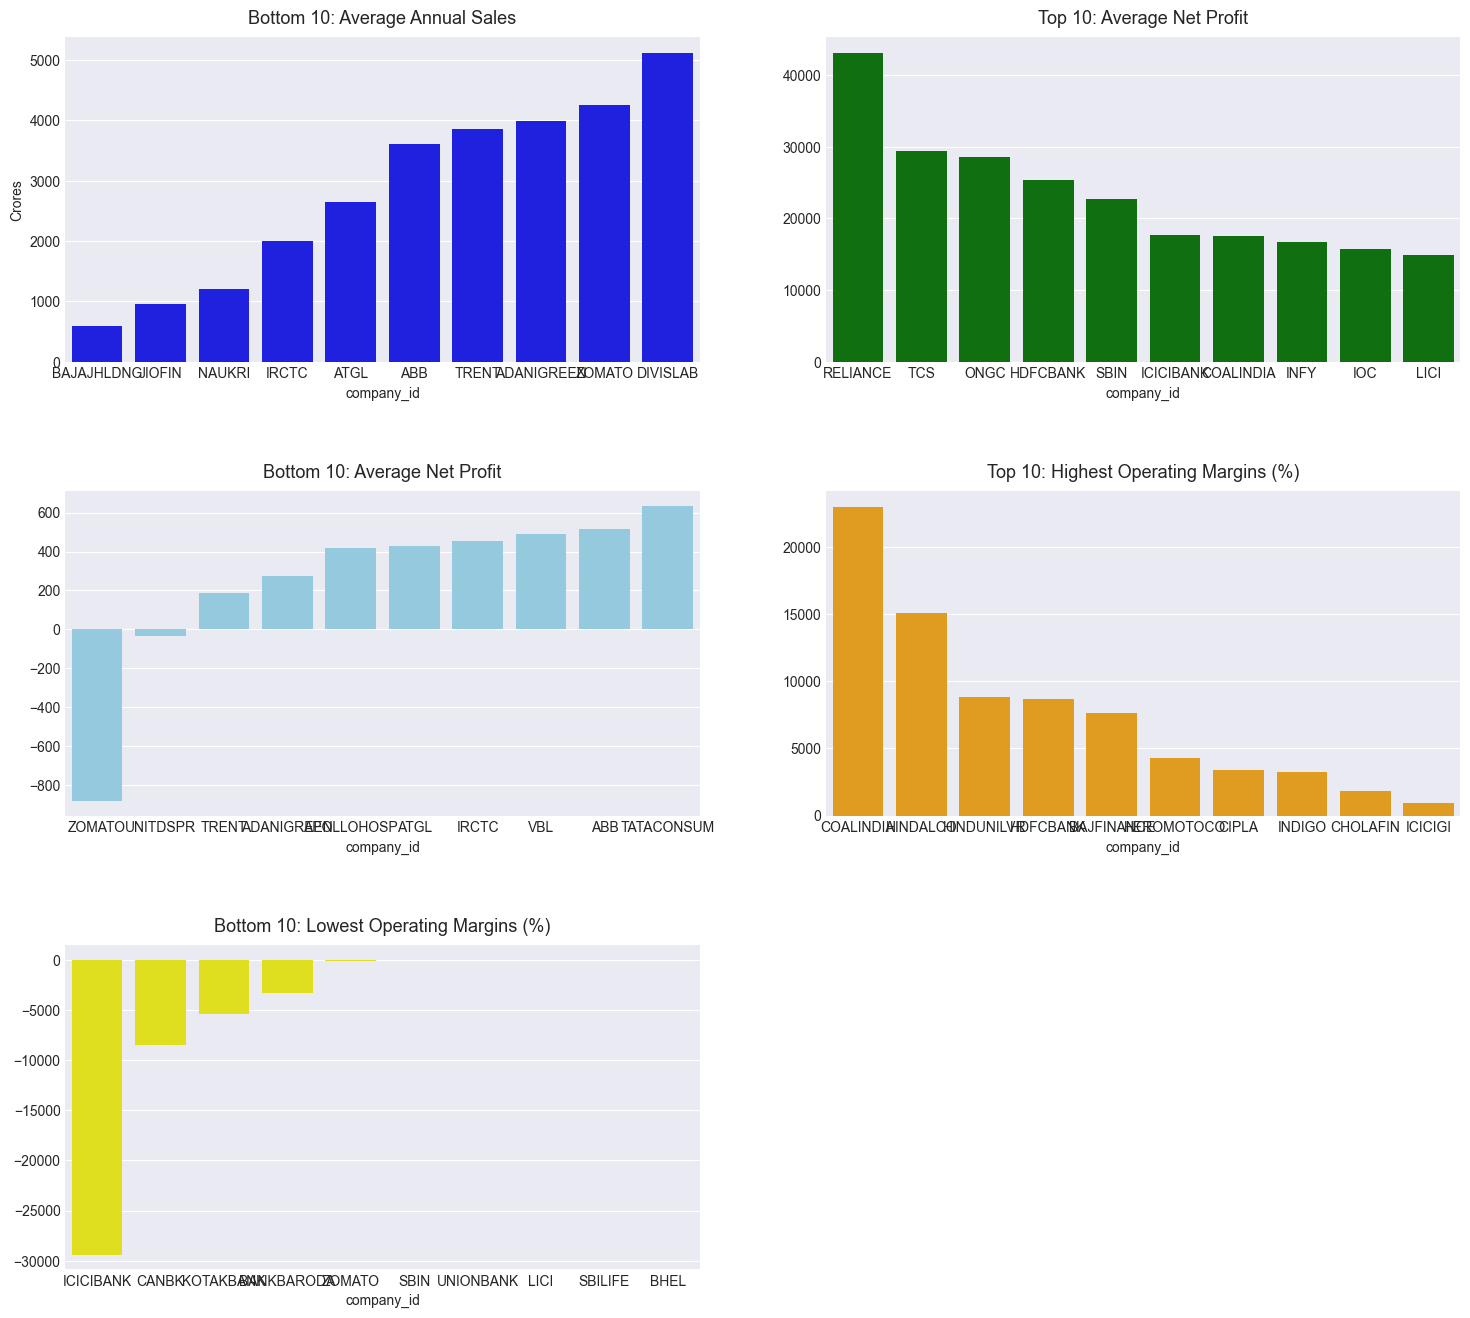

In [13]:
# Filter out 'TTM' to keep only historical fiscal years
historical_pl = df_pl[df_pl['year'] != 'TTM']

# Calculate the 12-year average for each company
company_avg = historical_pl.groupby('company_id')[['sales', 'net_profit', 'opm_percentage']].mean()

# Create the main blank canvas
plt.figure(figsize=(18, 16))
plt.subplots_adjust(hspace=0.4) # Add space between rows


# 1. Bottom 10 Sales (Revenue) - Slot 1 (Top Left)

plt.subplot(3, 2, 1)
bottom_10_sales = company_avg['sales'].sort_values().head(10)
sns.barplot(x=bottom_10_sales.index.astype(str), y=bottom_10_sales.values, color='blue') 
plt.title("Bottom 10: Average Annual Sales", fontsize=13, pad=10)
plt.ylabel("Crores")


# 2. Top 10 Net Profit - Slot 2 (Top Right)

plt.subplot(3, 2, 2)
top_10_np = company_avg['net_profit'].sort_values(ascending=False).head(10)
sns.barplot(x=top_10_np.index.astype(str), y=top_10_np.values, color='green') 
plt.title("Top 10: Average Net Profit", fontsize=13, pad=10)


# 3. Bottom 10 Net Profit - Slot 3 (Middle Left)

plt.subplot(3, 2, 3)
bottom_10_np = company_avg['net_profit'].sort_values().head(10)
sns.barplot(x=bottom_10_np.index.astype(str), y=bottom_10_np.values, color='skyblue') 
plt.title("Bottom 10: Average Net Profit", fontsize=13, pad=10)


# 4. Top 10 OPM% - Slot 4 (Middle Right)

plt.subplot(3, 2, 4)
top_10_opm = company_avg['opm_percentage'].sort_values(ascending=False).head(10)
sns.barplot(x=top_10_opm.index.astype(str), y=top_10_opm.values, color='orange') 
plt.title("Top 10: Highest Operating Margins (%)", fontsize=13, pad=10)


# 5. Bottom 10 OPM% - Slot 5 (Bottom Left)

plt.subplot(3, 2, 5)
bottom_10_opm = company_avg['opm_percentage'].sort_values().head(10)
sns.barplot(x=bottom_10_opm.index.astype(str), y=bottom_10_opm.values, color='yellow') 
plt.title("Bottom 10: Lowest Operating Margins (%)", fontsize=13, pad=10)

plt.show()

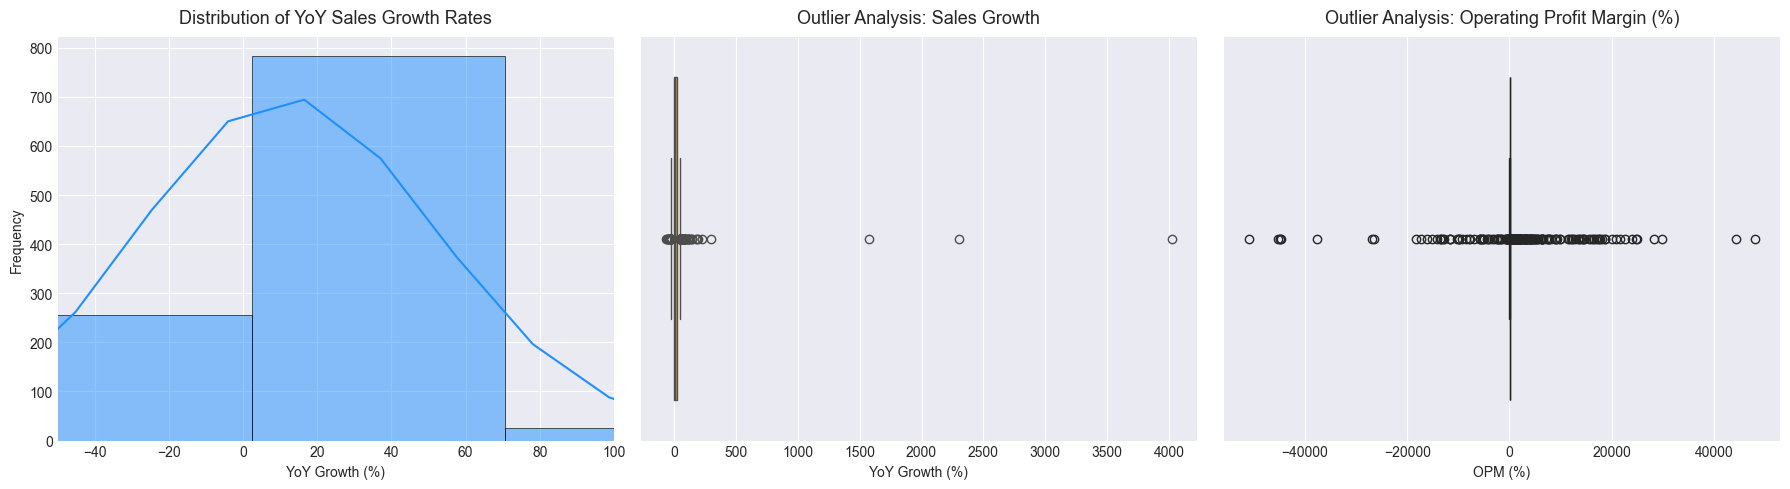

In [15]:
# 1. Sort the data properly by company and year so our math calculates chronologically
historical_pl = df_pl[df_pl['year'] != 'TTM'].copy()
historical_pl = historical_pl.sort_values(by=['company_id', 'year'])

# 2. Mathematically calculate Year-over-Year (YoY) Sales Growth Percentage
historical_pl['yoy_sales_growth_pct'] = historical_pl.groupby('company_id')['sales'].pct_change() * 100

# Drop the NaN values (the very first year for each company won't have a previous year to compare to)
growth_data = historical_pl.dropna(subset=['yoy_sales_growth_pct'])

# 3. Create a 1x3 grid for our charts
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: The Distribution of Sales Growth (Histogram + KDE)
sns.histplot(data=growth_data, x='yoy_sales_growth_pct', kde=True, ax=axes[0], color='dodgerblue', bins=60)
axes[0].set_title("Distribution of YoY Sales Growth Rates", fontsize=13, pad=10)
axes[0].set_xlabel("YoY Growth (%)")
axes[0].set_ylabel("Frequency")
axes[0].set_xlim(-50, 100) # We zoom in here to ignore extreme 1000% anomalies and view the "bell curve"

# Chart 2: Outlier Analysis for Growth (Boxplot)
sns.boxplot(data=growth_data, x='yoy_sales_growth_pct', ax=axes[1], color='orange')
axes[1].set_title("Outlier Analysis: Sales Growth", fontsize=13, pad=10)
axes[1].set_xlabel("YoY Growth (%)")

# Chart 3: Outlier Analysis for OPM% (Boxplot)
sns.boxplot(data=historical_pl, x='opm_percentage', ax=axes[2], color='purple')
axes[2].set_title("Outlier Analysis: Operating Profit Margin (%)", fontsize=13, pad=10)
axes[2].set_xlabel("OPM (%)")

plt.tight_layout()
plt.show()

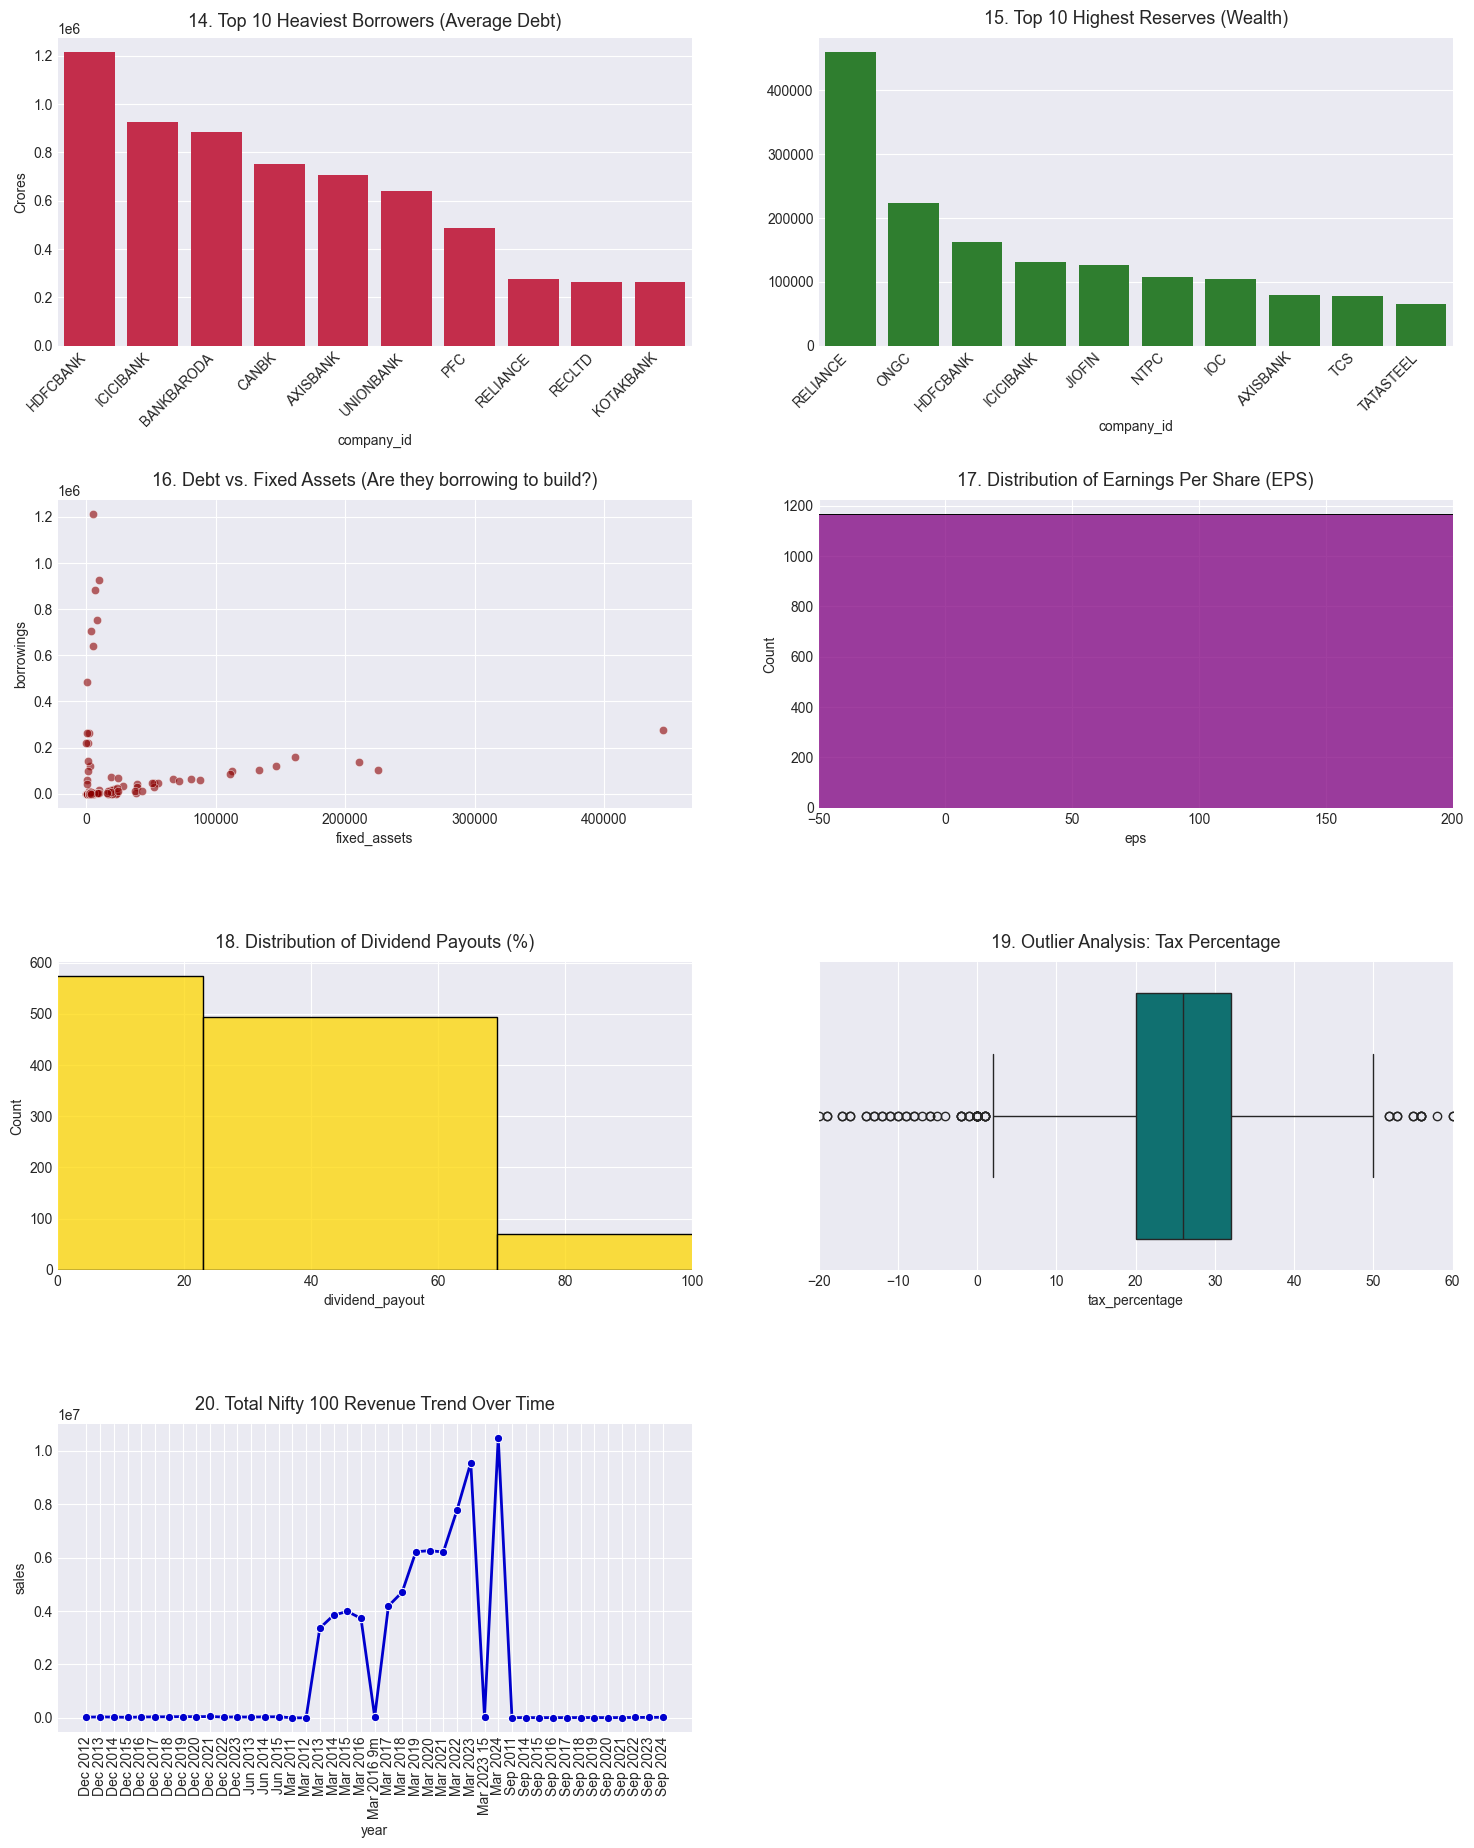

In [23]:
# 1. Clean the Balance Sheet to remove TTM (Trailing Twelve Months) if it exists
historical_bs = df_bs[df_bs['year'] != 'TTM'] if 'TTM' in df_bs['year'].values else df_bs

# Calculate average debt and wealth for each company
bs_avg = historical_bs.groupby('company_id')[['borrowings', 'reserves', 'fixed_assets']].mean()

# Create a massive 4x2 grid for our final 7 charts
plt.figure(figsize=(18, 22))
plt.subplots_adjust(hspace=0.5)

# ---------------------------------------------------------
# Chart 14: Top 10 Heaviest Borrowers
# ---------------------------------------------------------
plt.subplot(4, 2, 1)
top_debt = bs_avg['borrowings'].sort_values(ascending=False).head(10)
sns.barplot(x=top_debt.index.astype(str), y=top_debt.values, color='crimson')
plt.title("14. Top 10 Heaviest Borrowers (Average Debt)", fontsize=13, pad=8)
plt.ylabel("Crores")
plt.xticks(rotation=45,ha='right')

# ---------------------------------------------------------
# Chart 15: Top 10 Highest Reserves (Cash Rich)
# ---------------------------------------------------------
plt.subplot(4, 2, 2)
top_reserves = bs_avg['reserves'].sort_values(ascending=False).head(10)
sns.barplot(x=top_reserves.index.astype(str), y=top_reserves.values, color='forestgreen')
plt.title("15. Top 10 Highest Reserves (Wealth)", fontsize=13, pad=10)
plt.xticks(rotation=45,ha='right')

# ---------------------------------------------------------
# Chart 16: Scatter Plot - Debt vs Fixed Assets
# ---------------------------------------------------------
plt.subplot(4, 2, 3)
sns.scatterplot(data=bs_avg, x='fixed_assets', y='borrowings', color='darkred', alpha=0.6)
plt.title("16. Debt vs. Fixed Assets (Are they borrowing to build?)", fontsize=13, pad=10)

# ---------------------------------------------------------
# Chart 17: Distribution of Earnings Per Share (EPS)
# ---------------------------------------------------------
plt.subplot(4, 2, 4)
sns.histplot(data=historical_pl, x='eps', bins=60, color='purple')
plt.title("17. Distribution of Earnings Per Share (EPS)", fontsize=13, pad=10)
plt.xlim(-50, 200) # Zooming in to exclude extreme outliers

# ---------------------------------------------------------
# Chart 18: Distribution of Dividend Payouts
# ---------------------------------------------------------
plt.subplot(4, 2, 5)
sns.histplot(data=historical_pl, x='dividend_payout', bins=40, color='gold')
plt.title("18. Distribution of Dividend Payouts (%)", fontsize=13, pad=10)
plt.xlim(0, 100)

# ---------------------------------------------------------
# Chart 19: Outlier Analysis - Tax Percentage
# ---------------------------------------------------------
plt.subplot(4, 2, 6)
sns.boxplot(data=historical_pl, x='tax_percentage', color='teal')
plt.title("19. Outlier Analysis: Tax Percentage", fontsize=13, pad=10)
plt.xlim(-20, 60) # Zooming in to standard tax brackets

# ---------------------------------------------------------
# Chart 20: Total Nifty 100 Revenue Trend
# ---------------------------------------------------------
plt.subplot(4, 2, 7)
yearly_sales = historical_pl.groupby('year')['sales'].sum().reset_index()
sns.lineplot(data=yearly_sales, x='year', y='sales', marker='o', color='mediumblue', linewidth=2)
plt.title("20. Total Nifty 100 Revenue Trend Over Time", fontsize=13, pad=10)
plt.xticks(rotation=90)

# Turn off the empty 8th slot
plt.subplot(4, 2, 8).axis('off')

plt.show()

# Exploratory Data Analysis: Top 5 Key Insights

1. Massive Top-Line Skew (The Market Giants): The Nifty 100 revenue distribution is heavily skewed right. A fraction of mega-corporations (e.g., LICI, Reliance) completely dominate total sales, meaning standard averages will be heavily warped by these outliers.

2. Strong P&L Correlations: There is a highly significant positive correlation (0.84) between Sales and Net Profit. However, Expenses scale at a near 1.00 correlation with Sales, indicating the immense operational costs of maintaining Nifty 100 scale.

3. Loss-Making Giants: Inclusion in the Nifty 100 does not guarantee absolute profitability. The Bottom 10 Net Profit analysis reveals that several companies have operated at multi-thousand-crore average losses over the last decade.

4. Debt-Driven Asset Moats: The balance sheet analysis shows a clear relationship between heavy borrowing and large fixed-asset bases, specifically dominated by banking and heavy infrastructure sectors.

5. Data Engineering Requirements: Critical health metrics like ROE and Compounded Growth are currently unusable for Machine Learning, as they are stored as unstructured text strings (e.g., "10 Years: 21%"). A custom ETL parsing pipeline is strictly required for the next phase.